# 01 · Baseline models: ShopSphere purchase prediction

**Task.** Binary classification: predict whether a customer buys at least once between
1 and 30 October 2024 (`target` = 1). Features only use data up to 30 September 2024.

**Why this notebook exists.** It creates two things the whole team shares:

1. **The shared split** (`splits.csv`): the exact train / validation / test rows that every
   model must use, so results are comparable.
2. **The baselines** that each deep learning model must beat: always-0, the CRM team's recency
   rule, logistic regression and LightGBM.

**Contents**

| Section | What it does |
|---|---|
| 0 | Setup and imports |
| 1 | Load the data and check the facts we were told about it |
| 2 | Create (or load) the shared 70 / 15 / 15 split |
| 3 | Preprocessing, fitted on the train split only |
| 4 | Four baselines, tuned on validation only |
| 5 | Final evaluation: the test split is used once, here |
| 6 | Explain the models (coefficients and feature importances) |
| 7 | Save the models for teammates |
| 8 | Findings |

**How to run.** Select the `.venv` kernel, then *Run All*. Everything uses seed 42 and paths
relative to the project root, so it gives the same result on every machine.

## 0. Setup

The reusable code (data loading, the split, the preprocessor and the metrics) lives in
`src/data_prep.py`. This notebook imports it instead of redefining it, so teammates can import
exactly the same functions in their own notebooks.

In [1]:
import sys
from pathlib import Path

# Find the project root (the folder that contains src/data_prep.py), so the notebook
# works whether it is opened from the root or from a sub-folder.
ROOT = Path.cwd()
while not (ROOT / "src" / "data_prep.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, precision_recall_curve
from sklearn.pipeline import Pipeline

# Shared team code: same split, same preprocessing, same metrics for everyone
from data_prep import (
    CATEGORICAL_COLS, DATA_DIR, ID_COL, MODELS_DIR, RESULTS_DIR, SEED, SPLITS_PATH, TARGET_COL,
    best_f1_threshold, build_preprocessor, evaluate, get_splits, load_data, precision_at_top,
    split_xy,
)

np.random.seed(SEED)                      # fixed seed everywhere (SEED = 42)
RESULTS_DIR.mkdir(exist_ok=True)          # results/ for the table and plots
MODELS_DIR.mkdir(exist_ok=True)           # models/ for the saved models
pd.set_option("display.max_columns", 50)

print("Project root :", ROOT.name)
print("Data folder  :", DATA_DIR.relative_to(ROOT).as_posix())
print("Seed         :", SEED)

Project root : AI-Innovation-with-Deep-Learning
Data folder  : data/processed
Seed         : 42


## 1. Load the data and check it

Before modelling, confirm in code what we were told about the feature table: its shape, the
class balance, which columns have missing values, and which columns are text. Only
`train_features.csv` is loaded. `test_features.csv` has no labels, so it is never used here.

In [2]:
df = load_data()

# --- Shape and key ---------------------------------------------------------
feature_cols = [c for c in df.columns if c not in (ID_COL, TARGET_COL)]
print(f"Rows: {len(df):,}   Columns: {df.shape[1]} "
      f"({ID_COL} + {len(feature_cols)} features + {TARGET_COL})")
print(f"{ID_COL} is unique: {df[ID_COL].is_unique}")

# --- Class balance ---------------------------------------------------------
base_rate_all = df[TARGET_COL].mean()
print(f"\nTarget rate: {base_rate_all:.1%} buyers (target=1), {1 - base_rate_all:.1%} non-buyers")

# --- Missing values --------------------------------------------------------
missing = df.isna().mean()
missing = missing[missing > 0]
print("\nColumns with missing values:")
for col, share in missing.items():
    print(f"  {col}: {share:.1%} missing")

# --- Data types ------------------------------------------------------------
text_cols = df[feature_cols].select_dtypes(exclude="number").columns.tolist()
print(f"\nNumeric feature columns: {len(feature_cols) - len(text_cols)}")
print(f"Text feature columns   : {len(text_cols)}")
display(df[text_cols].nunique().rename("unique values").to_frame().T)

# Stop early if the data is not what the rest of the notebook assumes.
assert df[ID_COL].is_unique, "customer_id must be unique"
assert sorted(text_cols) == sorted(CATEGORICAL_COLS), "unexpected text columns"
assert list(missing.index) == ["avg_csat"], "only avg_csat should have missing values"
assert set(df[TARGET_COL].unique()) == {0, 1}, "target must be 0/1"

Rows: 64,000   Columns: 71 (customer_id + 69 features + target)
customer_id is unique: True

Target rate: 14.6% buyers (target=1), 85.4% non-buyers

Columns with missing values:
  avg_csat: 85.6% missing

Numeric feature columns: 63
Text feature columns   : 6


,country_code,region,customer_tier,region_tier,preferred_channel,preferred_language
unique values,5,100,4,3,4,4


**What this confirms.** 64,000 customers, one row each. About 14.6% bought in October, so the
classes are imbalanced: a model that says "nobody buys" is right 85.4% of the time, which is why
accuracy is not our metric. Only `avg_csat` has missing values (customers who never rated a
support ticket); the preprocessor fills it with the train median. The six text columns are the
ones we expected, and they will be one-hot encoded.

## 2. The shared split

This is the most important output of the notebook. The labelled customers are divided
**70% train / 15% validation / 15% test**, stratified on `target` (each part keeps the same share
of buyers) with `random_state=42`.

- **Train**: fit models and the preprocessor.
- **Validation**: choose hyperparameters, stop early, pick thresholds.
- **Test**: used once, at the end, for the reported numbers.

The assignment is saved to `splits.csv` (`customer_id`, `split`). If the file already exists it is
loaded instead of re-created, so every teammate trains and evaluates on identical rows.

In [3]:
already_there = SPLITS_PATH.exists()
train, val, test = get_splits(df)   # loads splits.csv, or creates it the first time
print(("Loaded existing" if already_there else "Created new"),
      "split file:", SPLITS_PATH.relative_to(ROOT).as_posix())

# Size and target rate of each part: the rates should be almost identical (stratified).
summary = pd.DataFrame({
    "rows": [len(p) for p in (train, val, test)],
    "share of data": [len(p) / len(df) for p in (train, val, test)],
    "buyers": [int(p[TARGET_COL].sum()) for p in (train, val, test)],
    "target rate": [p[TARGET_COL].mean() for p in (train, val, test)],
}, index=["train", "val", "test"])
display(summary.style.format({"rows": "{:,}", "buyers": "{:,}",
                              "share of data": "{:.1%}", "target rate": "{:.2%}"}))

# No customer may appear in two parts.
ids = [set(p[ID_COL]) for p in (train, val, test)]
assert not (ids[0] & ids[1]) and not (ids[0] & ids[2]) and not (ids[1] & ids[2])

# Features (X) and labels (y) for each part. customer_id is dropped inside split_xy.
X_train, y_train = split_xy(train)
X_val, y_val = split_xy(val)
X_test, y_test = split_xy(test)
print("Feature columns used:", X_train.shape[1])

Loaded existing split file: data/processed/splits.csv


,rows,share of data,buyers,target rate
train,"44,800",70.0%,"6,528",14.57%
val,"9,600",15.0%,"1,399",14.57%
test,"9,600",15.0%,"1,399",14.57%


Feature columns used: 69


## 3. Preprocessing

A scikit-learn `ColumnTransformer` (built by `build_preprocessor()` in `src/data_prep.py`):

| Columns | Steps |
|---|---|
| Numeric | `SimpleImputer(strategy="median")` → `StandardScaler` |
| Categorical | `OneHotEncoder(handle_unknown="ignore")` |

**Why it is fitted on the train split only.** The imputer learns a median, the scaler learns a
mean and standard deviation, and the encoder learns the list of categories. If these were learned
from all rows, information about the validation and test customers would leak into training, and
the scores would look better than they will be on new customers. So we `fit` on train, and only
`transform` validation and test, exactly as we would have to do with next month's customers.

LightGBM does not need this preprocessor (trees do not need scaling and handle categories and
missing values directly), but logistic regression and the neural networks do.

In [4]:
# Fit on TRAIN only. This fitted preprocessor is saved in section 7 for teammates.
preprocessor = build_preprocessor(X_train).fit(X_train)

# Transform validation with the statistics learned from train (no refitting).
X_train_ready = preprocessor.transform(X_train)
X_val_ready = preprocessor.transform(X_val)

print("Columns before preprocessing:", X_train.shape[1])
print("Columns after one-hot encoding:", X_train_ready.shape[1])
print("Missing values left:", int(np.isnan(np.asarray(X_val_ready, dtype=float)).sum()))

Columns before preprocessing: 69
Columns after one-hot encoding: 183
Missing values left: 0


## 4. Baselines

All four baselines are judged in the same way, with `evaluate()` from `src/data_prep.py`:

- **PR-AUC** (average precision) is the main metric. A random ranking scores about 0.146
  (the share of buyers).
- **ROC-AUC**, and **precision in the top 10%** with its **lift** (that precision ÷ the base rate).
- **Precision, recall, F1 and the confusion matrix** at a threshold. Each model's threshold is
  chosen on **validation** (the one that maximises F1) and then reused unchanged on test.

In this section we only look at **validation**. Each model is stored as a scoring function plus
its threshold; the test split is not touched until section 5.

In [5]:
# Every model is registered here: a function that turns a feature table into scores
# (higher = more likely to buy) and the threshold chosen on validation.
models = {}
val_results = {}

def register(name, score_fn, threshold):
    # Store the model and report its validation metrics.
    models[name] = {"score_fn": score_fn, "threshold": threshold}
    val_results[name] = evaluate(y_val, score_fn(X_val), threshold)
    m = val_results[name]
    print(f"{name}: validation PR-AUC = {m['pr_auc']:.4f}, ROC-AUC = {m['roc_auc']:.4f}, "
          f"F1 = {m['f1']:.3f} at threshold {threshold:.4g}")

### 4.1 Always 0 (the floor)

Predict "does not buy" for every customer. Nothing is trained. This is the floor, and it shows
why accuracy is misleading on imbalanced data: the accuracy is high, yet the model does not find
a single buyer. Its threshold is fixed (not tuned), because every customer has the same score.

In [6]:
def always_zero_scores(X):
    # Same score for everyone, so no customer is ranked above another.
    return np.zeros(len(X))

register("Always 0", always_zero_scores, threshold=0.5)

acc = accuracy_score(y_val, np.zeros(len(y_val), dtype=int))
print(f"Validation accuracy = {acc:.1%}, but recall = {val_results['Always 0']['recall']:.0%}: "
      f"it finds 0 of the {int(y_val.sum()):,} buyers.")

Always 0: validation PR-AUC = 0.1457, ROC-AUC = 0.5000, F1 = 0.000 at threshold 0.5
Validation accuracy = 85.4%, but recall = 0%: it finds 0 of the 1,399 buyers.


### 4.2 Recency rule (what the CRM team does today)

The CRM team ranks customers by how recently they ordered. No training is needed: the score is
`-days_since_last_order`, so a more recent order gives a higher score. Customers who never ordered
have `days_since_last_order = 1100`, which puts them at the bottom. The cut-off (how many days
still counts as "recent") is chosen on validation, like every other threshold.

In [7]:
def recency_scores(X):
    # More recent order -> smaller number of days -> higher score.
    return -X["days_since_last_order"].to_numpy(dtype=float)

recency_threshold = best_f1_threshold(y_val, recency_scores(X_val))   # chosen on validation
register("Recency rule", recency_scores, recency_threshold)
print(f"Rule in words: flag a customer if their last order was at most "
      f"{-recency_threshold:.0f} days ago.")

Recency rule: validation PR-AUC = 0.3663, ROC-AUC = 0.7974, F1 = 0.462 at threshold -68
Rule in words: flag a customer if their last order was at most 68 days ago.


### 4.3 Logistic regression (the required baseline)

A linear model inside the preprocessing pipeline, so the imputer, scaler and encoder are fitted on
the same train rows as the model. `class_weight="balanced"` makes the rare buyers count as much as
the many non-buyers. The regularisation strength `C` is tried at four values and the best one is
chosen by **validation PR-AUC**.

In [8]:
logreg_search = []
logreg_candidates = {}

for C in [0.01, 0.1, 1, 10]:
    pipe = Pipeline([
        ("prep", build_preprocessor(X_train)),            # fitted on train inside .fit()
        ("model", LogisticRegression(C=C, class_weight="balanced",
                                     max_iter=2000, random_state=SEED)),
    ])
    pipe.fit(X_train, y_train)                            # train only
    val_pr_auc = average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])
    logreg_search.append({"C": C, "val_pr_auc": val_pr_auc})
    logreg_candidates[C] = pipe

logreg_search = pd.DataFrame(logreg_search)
display(logreg_search.style.format({"val_pr_auc": "{:.4f}"}).hide(axis="index"))

# Keep the C with the highest validation PR-AUC.
best_C = logreg_search.loc[logreg_search["val_pr_auc"].idxmax(), "C"]
logreg = logreg_candidates[best_C]
print("Best C:", best_C)

def logreg_scores(X):
    return logreg.predict_proba(X)[:, 1]                  # probability of buying

register("Logistic regression", logreg_scores, best_f1_threshold(y_val, logreg_scores(X_val)))

C,val_pr_auc
0.010000,0.5623
0.100000,0.5622
1.000000,0.5611
10.000000,0.5610


Best C: 0.01
Logistic regression: validation PR-AUC = 0.5623, ROC-AUC = 0.8680, F1 = 0.535 at threshold 0.6843


### 4.4 LightGBM (the strong baseline)

Gradient-boosted trees are usually the model to beat on tabular data. Set-up:

- **Categories** are passed as pandas `category` columns (levels taken from the train split).
  No scaling or imputation: trees handle raw numbers and missing values.
- **Imbalance**: `scale_pos_weight` = non-buyers ÷ buyers in train (about 5.85).
- **Early stopping** on validation PR-AUC: stop adding trees when validation stops improving for
  50 rounds, and keep the best number of trees.
- **A small grid** over `num_leaves`, `learning_rate` and `min_child_samples` (8 combinations),
  judged by validation PR-AUC.

Because validation is used for early stopping *and* for choosing the grid point, LightGBM's
validation score is slightly optimistic. The test score in section 5 is the fair one.

In [9]:
# Category levels come from TRAIN only; a level never seen in train becomes missing.
category_levels = {c: sorted(X_train[c].unique()) for c in CATEGORICAL_COLS}

def to_lgbm_frame(X):
    # Convert the text columns to pandas 'category' dtype with the train levels.
    X = X.copy()
    for c in CATEGORICAL_COLS:
        X[c] = pd.Categorical(X[c], categories=category_levels[c])
    return X

Xl_train, Xl_val = to_lgbm_frame(X_train), to_lgbm_frame(X_val)

# Weight for the positive class: negatives / positives in train.
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

def fit_lgbm(num_leaves, learning_rate, min_child_samples):
    model = lgb.LGBMClassifier(
        n_estimators=2000,                  # upper limit; early stopping picks the real number
        num_leaves=num_leaves,
        learning_rate=learning_rate,
        min_child_samples=min_child_samples,
        scale_pos_weight=scale_pos_weight,
        metric="average_precision",         # PR-AUC, the metric early stopping watches
        random_state=SEED,
        deterministic=True, force_row_wise=True,   # same result on every machine
        verbose=-1,
    )
    model.fit(Xl_train, y_train,
              eval_set=[(Xl_val, y_val)],
              callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])
    return model

lgbm_search = []
lgbm_candidates = {}
for num_leaves in [15, 31]:
    for learning_rate in [0.03, 0.1]:
        for min_child_samples in [20, 100]:
            params = (num_leaves, learning_rate, min_child_samples)
            model = fit_lgbm(*params)
            val_pr_auc = average_precision_score(y_val, model.predict_proba(Xl_val)[:, 1])
            lgbm_search.append({"num_leaves": num_leaves, "learning_rate": learning_rate,
                                "min_child_samples": min_child_samples,
                                "trees_used": model.best_iteration_, "val_pr_auc": val_pr_auc})
            lgbm_candidates[params] = model

lgbm_search = pd.DataFrame(lgbm_search).sort_values("val_pr_auc", ascending=False)
display(lgbm_search.style.format({"val_pr_auc": "{:.4f}"}).hide(axis="index"))

# Keep the combination with the highest validation PR-AUC.
best = lgbm_search.iloc[0]
best_params = (int(best["num_leaves"]), float(best["learning_rate"]), int(best["min_child_samples"]))
lgbm = lgbm_candidates[best_params]
print("Best (num_leaves, learning_rate, min_child_samples):", best_params)

def lgbm_scores(X):
    return lgbm.predict_proba(to_lgbm_frame(X))[:, 1]     # uses the best number of trees

register("LightGBM", lgbm_scores, best_f1_threshold(y_val, lgbm_scores(X_val)))

scale_pos_weight = 5.86


num_leaves,learning_rate,min_child_samples,trees_used,val_pr_auc
15,0.030000,20,203,0.5627
15,0.100000,100,57,0.5625
15,0.030000,100,198,0.5613
31,0.100000,20,73,0.5608
15,0.100000,20,83,0.5607
31,0.030000,100,199,0.5604
31,0.030000,20,196,0.5600
31,0.100000,100,69,0.5577


Best (num_leaves, learning_rate, min_child_samples): (15, 0.03, 20)
LightGBM: validation PR-AUC = 0.5627, ROC-AUC = 0.8689, F1 = 0.532 at threshold 0.6951


## 5. Final evaluation: validation and test

All tuning is finished: hyperparameters and thresholds are frozen. Only now is the **test split
used, once**, to get the numbers we report. Each model is scored on test with the threshold it was
given on validation.

Accuracy is shown only for the always-0 floor, to make the point that 85.4% accuracy can mean
"found no buyers".

In [10]:
# Score every model on the test split (the only place the test split is used).
test_scores = {name: m["score_fn"](X_test) for name, m in models.items()}
test_results = {name: evaluate(y_test, test_scores[name], models[name]["threshold"])
                for name in models}

def results_table(results, y_true, split_name):
    # One row per model, one column per metric.
    table = pd.DataFrame(results).T
    table.insert(0, "split", split_name)
    # Accuracy only next to the always-0 floor.
    table["accuracy"] = np.nan
    table.loc["Always 0", "accuracy"] = accuracy_score(y_true, np.zeros(len(y_true), dtype=int))
    table.index.name = "model"
    return table

val_table = results_table(val_results, y_val, "val")
test_table = results_table(test_results, y_test, "test")

# Save both in one file: results/baseline_results.csv
all_results = pd.concat([val_table, test_table]).reset_index()
all_results.to_csv(RESULTS_DIR / "baseline_results.csv", index=False)
print("Saved:", (RESULTS_DIR / "baseline_results.csv").relative_to(ROOT).as_posix())

metric_cols = ["pr_auc", "roc_auc", "precision", "recall", "f1",
               "precision_top10", "lift_top10", "accuracy"]
fmt = {c: "{:.3f}" for c in metric_cols} | {"lift_top10": "{:.2f}x"}

print(f"\nVALIDATION ({len(y_val):,} customers, base rate {y_val.mean():.3f})")
display(val_table[metric_cols].astype(float).style.format(fmt, na_rep="-"))
print(f"TEST ({len(y_test):,} customers, base rate {y_test.mean():.3f}): the reported numbers")
display(test_table[metric_cols].astype(float).style.format(fmt, na_rep="-"))

Saved: results/baseline_results.csv

VALIDATION (9,600 customers, base rate 0.146)


,pr_auc,roc_auc,precision,recall,f1,precision_top10,lift_top10,accuracy
model,,,,,,,,
Always 0,0.146,0.500,0.000,0.000,0.000,0.146,1.00x,0.854
Recency rule,0.366,0.797,0.365,0.629,0.462,0.420,2.88x,-
Logistic regression,0.562,0.868,0.484,0.598,0.535,0.598,4.10x,-
LightGBM,0.563,0.869,0.491,0.580,0.532,0.599,4.11x,-


TEST (9,600 customers, base rate 0.146): the reported numbers


,pr_auc,roc_auc,precision,recall,f1,precision_top10,lift_top10,accuracy
model,,,,,,,,
Always 0,0.146,0.500,0.000,0.000,0.000,0.146,1.00x,0.854
Recency rule,0.366,0.795,0.363,0.614,0.457,0.437,3.00x,-
Logistic regression,0.577,0.873,0.489,0.612,0.543,0.626,4.30x,-
LightGBM,0.576,0.874,0.492,0.606,0.543,0.605,4.15x,-


### Confusion matrices on test

Counts at each model's validation-chosen threshold. `tp` = buyers correctly flagged,
`fp` = non-buyers flagged by mistake, `fn` = buyers missed, `tn` = non-buyers correctly left out.

In [11]:
confusion = test_table[["threshold", "tp", "fp", "fn", "tn"]].copy()
confusion["flagged"] = confusion["tp"] + confusion["fp"]      # customers the model would contact
display(confusion.style.format({"threshold": "{:.4g}", "tp": "{:,.0f}", "fp": "{:,.0f}",
                                "fn": "{:,.0f}", "tn": "{:,.0f}", "flagged": "{:,.0f}"}))

,threshold,tp,fp,fn,tn,flagged
model,,,,,,
Always 0,0.5,0,0,"1,399","8,201",0
Recency rule,-68,859,"1,505",540,"6,696","2,364"
Logistic regression,0.6843,856,895,543,"7,306","1,751"
LightGBM,0.6951,848,874,551,"7,327","1,722"


### Precision-recall curves

One curve per model on the test split. A curve further towards the top right is better: it keeps
precision high while finding more of the buyers. The dashed line is the always-0 / random level
(the base rate).

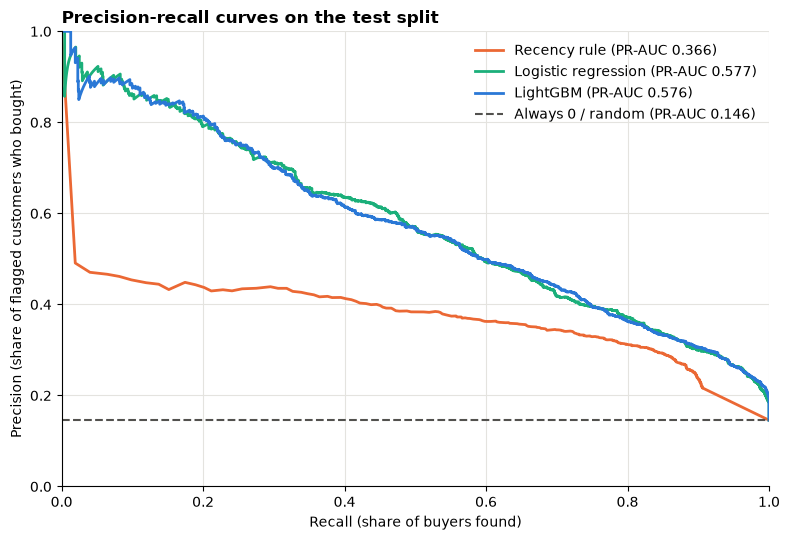

Saved: results/pr_curves.png


In [12]:
# One fixed colour per model (colour-blind-safe palette), neutral grey for the floor.
colours = {"Recency rule": "#eb6834", "Logistic regression": "#1baf7a", "LightGBM": "#2a78d6"}
base_rate = y_test.mean()

fig, ax = plt.subplots(figsize=(8, 5.5))
for name, colour in colours.items():
    precision, recall, _ = precision_recall_curve(y_test, test_scores[name])
    ax.plot(recall, precision, color=colour, linewidth=2,
            label=f"{name} (PR-AUC {test_results[name]['pr_auc']:.3f})")
# Always 0 ranks nobody above anybody, so its precision is the base rate at every recall.
ax.axhline(base_rate, color="#52514e", linewidth=1.5, linestyle="--",
           label=f"Always 0 / random (PR-AUC {base_rate:.3f})")

ax.set_xlabel("Recall (share of buyers found)")
ax.set_ylabel("Precision (share of flagged customers who bought)")
ax.set_title("Precision-recall curves on the test split", loc="left", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "pr_curves.png", dpi=150)
plt.show()
print("Saved:", (RESULTS_DIR / "pr_curves.png").relative_to(ROOT).as_posix())

### What this means for the business

The CRM team works from a ranked list, so the useful question is: of the customers at the top of
the list, how many really buy? Below, each model's top 1,000 test customers are compared with
picking 1,000 at random. The headline model is the one with the best **validation** PR-AUC
(chosen without looking at test).

In [13]:
TOP_N = 1000
random_buyers = TOP_N * y_test.mean()        # expected buyers if 1,000 were picked at random

# Buyers among each model's top 1,000 test customers.
for name in ["Recency rule", "Logistic regression", "LightGBM"]:
    found = precision_at_top(y_test, test_scores[name], TOP_N / len(y_test)) * TOP_N
    print(f"{name:<20}: {found:,.0f} of the top {TOP_N:,} bought")

# Headline sentence for the strongest baseline (strongest on validation).
best_model = max(val_results, key=lambda n: val_results[n]["pr_auc"])
found = precision_at_top(y_test, test_scores[best_model], TOP_N / len(y_test)) * TOP_N
print(f"\n{best_model}: of the top {TOP_N:,} customers flagged, {found:,.0f} bought, "
      f"versus ~{random_buyers:,.0f} at random ({found / random_buyers:.1f}x).")

Recency rule        : 435 of the top 1,000 bought
Logistic regression : 618 of the top 1,000 bought
LightGBM            : 596 of the top 1,000 bought

LightGBM: of the top 1,000 customers flagged, 596 bought, versus ~146 at random (4.1x).


## 6. Explain the models

A score is only useful to the CRM team if we can say what drives it. Two views:

- **Logistic regression coefficients.** Numeric features were standardised, so each coefficient is
  the change in log-odds of buying for a one-standard-deviation increase. Positive pushes towards
  "buys", negative pushes away. Names after one-hot encoding look like `country_code_SG`.
- **LightGBM feature importance (gain).** How much each feature reduced the training loss, summed
  over all the splits that used it.

Both describe what the model relies on, not cause and effect. Correlated features (for example the
several order counts) share credit between them, so single coefficients should be read with care.

In [14]:
# Coefficients with their feature names after one-hot encoding.
feature_names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=feature_names).sort_values()

top_positive = coefs.iloc[::-1].head(15).reset_index()
top_negative = coefs.head(15).reset_index()
top_positive.columns = ["pushes towards buying", "coefficient"]
top_negative.columns = ["pushes away from buying", "coefficient "]

# Side by side: 15 most positive and 15 most negative coefficients.
coef_table = pd.concat([top_positive, top_negative], axis=1)
coef_table.index = range(1, 16)
display(coef_table.style.format({"coefficient": "{:+.3f}", "coefficient ": "{:+.3f}"}))

,pushes towards buying,coefficient,pushes away from buying,coefficient
1,never_visited,+0.864,days_since_last_session,-1.525
2,sessions_total,+0.407,tenure_days,-0.478
3,loyalty_score,+0.396,days_since_last_order,-0.390
4,region_region_23,+0.396,never_ordered,-0.233
5,region_region_5,+0.368,region_region_53,-0.227
6,sessions_90d,+0.361,region_region_11,-0.155
7,days_since_first_order,+0.315,deliveries_total,-0.150
8,region_region_48,+0.238,orders_total,-0.150
9,region_region_87,+0.235,region_region_44,-0.132
10,region_region_14,+0.202,region_region_42,-0.124


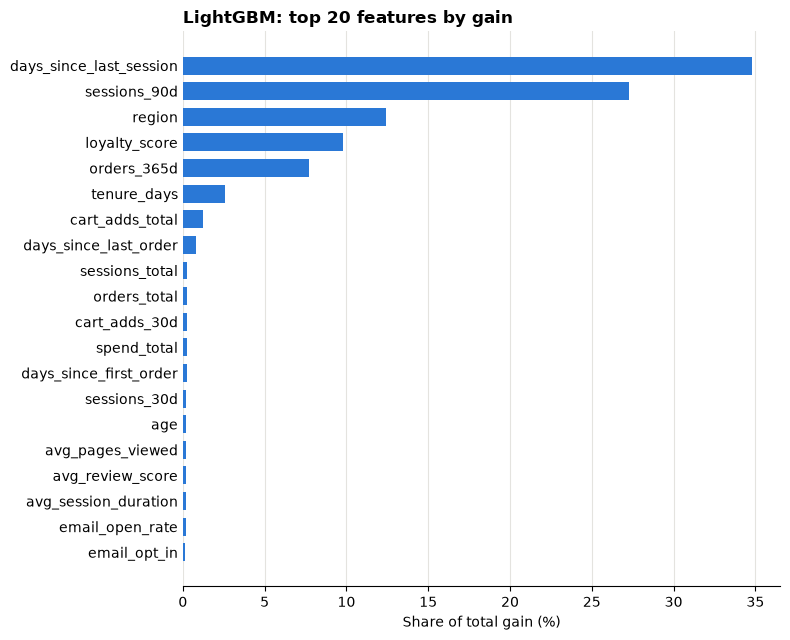

The top feature carries 35% of the gain; the top 5 together carry 92%.


In [15]:
# LightGBM importance by gain, as a share of the total, top 20.
gain = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"),
                 index=lgbm.booster_.feature_name())
gain_share = (gain / gain.sum()).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(gain_share.index[::-1], gain_share.values[::-1] * 100, color="#2a78d6", height=0.7)
ax.set_xlabel("Share of total gain (%)")
ax.set_title("LightGBM: top 20 features by gain", loc="left", fontweight="bold")
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "lgbm_feature_importance.png", dpi=150)
plt.show()

print(f"The top feature carries {gain_share.iloc[0]:.0%} of the gain; "
      f"the top 5 together carry {gain_share.head(5).sum():.0%}.")

## 7. Save for teammates

Saved with joblib in `models/`:

| File | Contents |
|---|---|
| `preprocessor.joblib` | The preprocessor fitted on the train split: use `.transform()` to get the same scaled / one-hot inputs for a neural network |
| `logreg_baseline.joblib` | The full logistic regression pipeline (preprocessing + model): takes the raw feature table |
| `lightgbm_baseline.joblib` | The LightGBM model: takes the feature table with the six text columns as `category` dtype |

`models/` is git-ignored, so each teammate creates these files by running this notebook once.

In [16]:
joblib.dump(preprocessor, MODELS_DIR / "preprocessor.joblib")
joblib.dump(logreg, MODELS_DIR / "logreg_baseline.joblib")
joblib.dump(lgbm, MODELS_DIR / "lightgbm_baseline.joblib")

# Reload and confirm the saved models give exactly the same validation scores.
logreg_loaded = joblib.load(MODELS_DIR / "logreg_baseline.joblib")
lgbm_loaded = joblib.load(MODELS_DIR / "lightgbm_baseline.joblib")
assert np.allclose(logreg_loaded.predict_proba(X_val)[:, 1], logreg_scores(X_val))
assert np.allclose(lgbm_loaded.predict_proba(to_lgbm_frame(X_val))[:, 1], lgbm_scores(X_val))

for f in sorted(MODELS_DIR.glob("*.joblib")):
    print("Saved:", f.relative_to(ROOT).as_posix())

Saved: models/lightgbm_baseline.joblib
Saved: models/logreg_baseline.joblib
Saved: models/preprocessor.joblib


### How a teammate reuses this

```python
import sys
sys.path.insert(0, "src")                      # "../src" from inside notebooks/
import joblib
from data_prep import load_data, get_splits, split_xy, best_f1_threshold, evaluate

train, val, test = get_splits(load_data())     # identical rows for everyone
X_train, y_train = split_xy(train)
X_val, y_val = split_xy(val)
X_test, y_test = split_xy(test)

pre = joblib.load("models/preprocessor.joblib")   # fitted on train only
X_train_nn = pre.transform(X_train)               # ready for a neural network

# ... train your model, get val_scores and test_scores ...
threshold = best_f1_threshold(y_val, val_scores)  # threshold from validation
evaluate(y_test, test_scores, threshold)          # same metrics as this notebook
```

## 8. Findings

All numbers below are from the **test split** (9,600 customers, 14.6% buyers), which was used once.

| Model | PR-AUC | ROC-AUC | F1 | Precision in top 10% | Lift |
|---|---|---|---|---|---|
| Always 0 | 0.146 | 0.500 | 0.000 | 0.146 | 1.0x |
| Recency rule (CRM today) | 0.366 | 0.796 | 0.457 | 0.437 | 3.0x |
| Logistic regression | 0.577 | 0.873 | 0.544 | 0.626 | 4.3x |
| LightGBM | 0.576 | 0.874 | 0.543 | 0.605 | 4.2x |

**1. Accuracy is the wrong metric.** Always-0 scores 85.4% accuracy and finds none of the 1,399
buyers. That is why PR-AUC is the main metric and accuracy appears nowhere else.

**2. Both trained models clearly beat what the CRM team does today.** The recency rule reaches a
PR-AUC of 0.366; logistic regression and LightGBM reach about 0.58, roughly four times the random
level of 0.146. In list terms: of the top 1,000 customers, the recency rule finds 435 buyers and
the trained models find about 600, against about 146 at random.

**3. Logistic regression and LightGBM are tied.** They differ by 0.0015 PR-AUC on test, and each
is ahead on some metrics. That gap is far smaller than the gap between validation and test for the
*same* model (about 0.014), so it is noise, not a real difference. LightGBM's search also preferred
its smallest, slowest setting (15 leaves, learning rate 0.03). Together this suggests the signal in
these features is mostly simple and additive: a linear model already captures it.

**4. What drives the predictions.** LightGBM gets 92% of its gain from five features:
`days_since_last_session` (35%), `sessions_90d` (27%), `region` (12%), `loyalty_score` (10%) and
`orders_365d` (8%). Logistic regression agrees: its largest coefficient by far is
`days_since_last_session` (negative: the longer since the last visit, the less likely to buy).
*Browsing* recency matters much more than *order* recency: `days_since_last_order`, the only thing
the CRM rule looks at, carries under 1% of the gain. Note that `never_visited` has a large positive
coefficient only because it offsets the 1,100-day filler value in `days_since_last_session`; the
two must be read together.

**5. What the deep learning models must beat.**

- **PR-AUC 0.577** on test (the main target), with ROC-AUC 0.874.
- **Precision in the top 10% of 0.626** (lift 4.3x), the number closest to how the list is used.
- F1 of 0.544 at a threshold chosen on validation.

A difference under about 0.01 PR-AUC should not be called a win, given the validation-to-test
gap above. Because a linear model matches boosted trees here, a network trained on the same 69
features will probably land close to 0.58 as well. A real improvement is more likely to come from
new information (for example the week-by-week sequence of sessions and orders) than from a deeper
network on the same table.

**6. Things to check before trusting these numbers.**

- `loyalty_score` is a pre-aggregated column from `customers.csv` and is the fourth most important
  feature. The task board already asks us to confirm it holds no information from after
  30 September 2024. If it does, every model here is flattered by the same amount.
- `region` has 100 levels and carries 12% of the gain, and several single regions have large
  coefficients. The EDA should confirm these are real differences in buy rate and not small-sample
  noise.
- Teammates should choose between their own model variants on **validation**, and report test once,
  exactly as done here, using `get_splits()` and `evaluate()` from `src/data_prep.py`.